# RiMEA 04: Measurement of the Fundamental Diagram

A long corridor (200 m x 10 m) with threee measuring points, one of which is the main measuring point with the other two functioning as control measuring points (RiMEA Guideline 4.1.1 Figure 5). The corridor is filled with different densities of persons with an equal as possible free walking speed of 1.2 m/s: 0.5 P/m^2 , 1 P/m^2 , 2 P/m^2 , 3 P/m^2. At measuring points, average speed of persons over 60 seconds (including 10 seconds of transient response) will be used to determine density. The corresponding fundamental diagrams are then created with **flow = speed * density**.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:45 CEST


In [2]:
from pathlib import Path
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario, run_sweep

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load the scenario

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-04-fundamental-diagram.zip"
base = load_scenario(str(SCENARIO_ZIP))
print(base.summary())

Scenario: scenario_files/Rimea-04-fundamental-diagram.zip
  Model:         WarpDriverModel
  Seed:          420
  Max time:      300s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~1000
    jps-distributions_0: 1000 agents


##  Sweep with N-Agents

In [6]:
sweep = run_sweep(
    base,
    axes={"num_agents": [1000,2000,4000,6000]},
    apply={"num_agents": lambda s, n: s.set_agent_count(0, n)},
    seeds=[42],
    workers=2,
)

df = sweep.to_dataframe()

In [7]:
# ---- Config ----
CORRIDOR_AREA = 200 * 10
FPS = 10.0
T_MIN, T_MAX = 10, 60

GATES = {
    "control1": {"x": 50, "x_tol": 1.0, "y_min": 6.0, "y_max": 8.0},
    "main":     {"x": 100, "x_tol": 1.0, "y_min": 6.0, "y_max": 8.0},
    "control2": {"x": 100, "x_tol": 1.0, "y_min": 4.0, "y_max": 6.0},
}


def compute_speeds(sqlite_path, fps=FPS, t_min=T_MIN, t_max=T_MAX, gates=GATES):
    conn = sqlite3.connect(sqlite_path)
    traj = pd.read_sql("SELECT frame, id, pos_x, pos_y FROM trajectory_data", conn)
    conn.close()

    traj = traj.sort_values(["id", "frame"])
    traj["time"] = traj["frame"] / fps
    traj["dx"] = traj.groupby("id")["pos_x"].diff()
    traj["dy"] = traj.groupby("id")["pos_y"].diff()
    traj["dt"] = traj.groupby("id")["time"].diff()
    traj["speed"] = np.sqrt(traj["dx"]**2 + traj["dy"]**2) / traj["dt"]

    traj = traj.dropna(subset=["speed"])
    traj = traj[traj["dt"] > 0]
    traj = traj[(traj["time"] >= t_min) & (traj["time"] <= t_max)]

    results = {}
    for gate_name, g in gates.items():
        near_gate = traj[
            (traj["pos_x"] >= g["x"] - g["x_tol"]) & (traj["pos_x"] <= g["x"] + g["x_tol"]) &
            (traj["pos_y"] >= g["y_min"]) & (traj["pos_y"] <= g["y_max"])
        ]
        results[gate_name] = near_gate["speed"].mean() if len(near_gate) > 0 else np.nan

    return results


def local_density_at_gate(sqlite_path, gate, fps=FPS, t_min=T_MIN, t_max=T_MAX):
    conn = sqlite3.connect(sqlite_path)
    traj = pd.read_sql("SELECT frame, id, pos_x, pos_y FROM trajectory_data", conn)
    conn.close()
    traj["time"] = traj["frame"] / fps
    window = traj[(traj["time"] >= t_min) & (traj["time"] <= t_max)]

    near_gate = window[
        (window["pos_x"] >= gate["x"] - gate["x_tol"]) & (window["pos_x"] <= gate["x"] + gate["x_tol"]) &
        (window["pos_y"] >= gate["y_min"]) & (window["pos_y"] <= gate["y_max"])
    ]

    gate_area = (2 * gate["x_tol"]) * (gate["y_max"] - gate["y_min"])
    counts_per_frame = near_gate.groupby("frame")["id"].nunique()
    if len(counts_per_frame) == 0:
        return np.nan
    return counts_per_frame.mean() / gate_area


# ---- Records with local density per gate ----
records = []
for _, row in df.iterrows():
    speeds = compute_speeds(row["sqlite_path"])
    for gate_name, speed in speeds.items():
        local_rho = local_density_at_gate(row["sqlite_path"], GATES[gate_name])
        records.append({
            "num_agents": row["num_agents"],
            "measuring_point": gate_name,
            "speed": speed,
            "density": local_rho,   # <- replaces nominal density
        })

speed_df = pd.DataFrame(records)
speed_df["flow"] = speed_df["speed"] * speed_df["density"]

summary = speed_df.sort_values(["measuring_point", "density"]).reset_index(drop=True)
print(summary)

    num_agents measuring_point     speed   density       flow
0         1000        control1       NaN       NaN        NaN
1         2000        control1       NaN       NaN        NaN
2         4000        control1       NaN       NaN        NaN
3         6000        control1       NaN       NaN        NaN
4         1000        control2  5.964618  1.050725   6.267171
5         2000        control2  5.966770  1.471429   8.779675
6         4000        control2  5.955616  1.956667  11.653155
7         6000        control2  5.936522  2.640625  15.676130
8         1000            main  5.965538  0.936508   5.586774
9         2000            main  5.968138  1.367857   8.163560
10        4000            main  5.956732  2.006757  11.953713
11        6000            main  5.935426  2.640625  15.673235


## Scenario figure

200 m x 10 m corridor with the main and the two control measuring areas of RiMEA Figure 5.

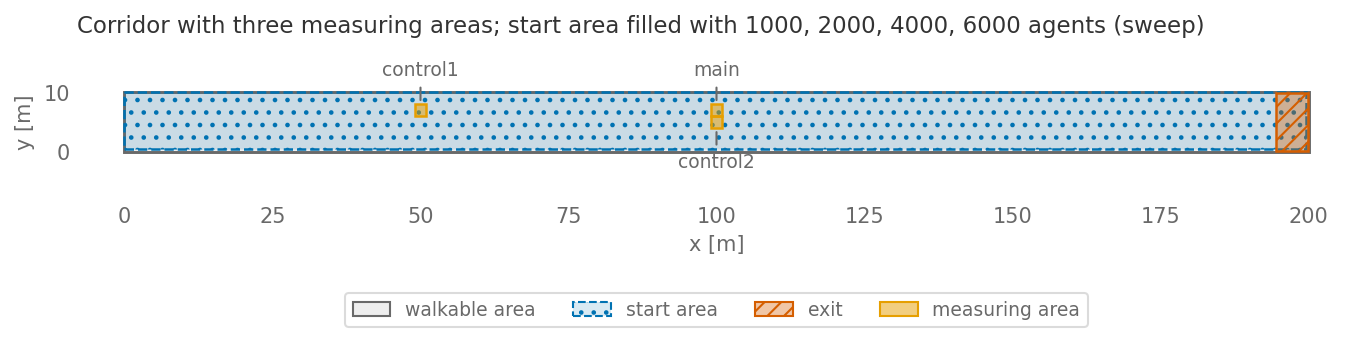

In [8]:
# Scenario geometry from the loaded ZIP with the three measuring areas.
from matplotlib.patches import Rectangle

with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(11, 2.8))
    handles = vv_draw_scenario(ax, base)
    for gate, g in GATES.items():
        ax.add_patch(Rectangle((g["x"] - g["x_tol"], g["y_min"]), 2 * g["x_tol"], g["y_max"] - g["y_min"],
                               facecolor=to_rgba(VV_ORANGE, 0.5), edgecolor=VV_ORANGE, linewidth=1.2, zorder=4))
        above = gate != "control2"
        ax.annotate(gate, xy=(g["x"], g["y_max"] if above else g["y_min"]),
                    xytext=(0, 12 if above else -12), textcoords="offset points", ha="center",
                    va="bottom" if above else "top", color="dimgrey", fontsize=9,
                    arrowprops={"arrowstyle": "-", "color": "dimgrey"})
    handles.append(Patch(facecolor=to_rgba(VV_ORANGE, 0.5), edgecolor=VV_ORANGE, label="measuring area"))
    counts = ", ".join(str(int(n)) for n in sorted(df["num_agents"].unique()))
    ax.set_title(f"Corridor with three measuring areas; start area filled with {counts} agents (sweep)", loc="left")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.55), ncol=4)
    plt.show()

##  Plot Fundamental Diagrams

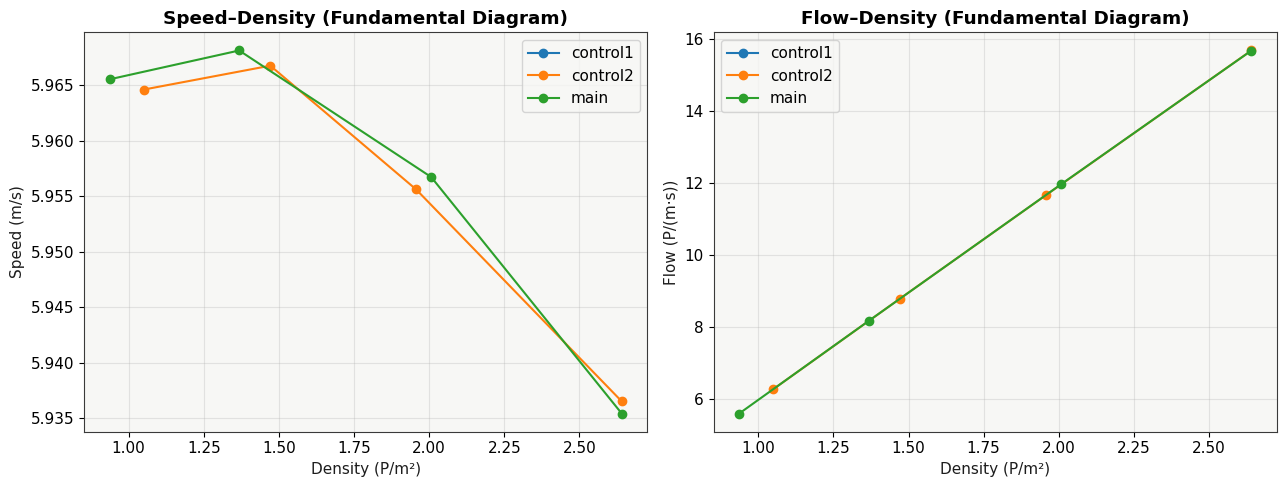

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for gate_name in summary["measuring_point"].unique():
    sub = summary[summary["measuring_point"] == gate_name]
    axes[0].plot(sub["density"], sub["speed"], marker="o", label=gate_name)
    axes[1].plot(sub["density"], sub["flow"], marker="o", label=gate_name)

axes[0].set_xlabel("Density (P/m²)")
axes[0].set_ylabel("Speed (m/s)")
axes[0].set_title("Speed–Density (Fundamental Diagram)")
axes[0].legend()

axes[1].set_xlabel("Density (P/m²)")
axes[1].set_ylabel("Flow (P/(m·s))")
axes[1].set_title("Flow–Density (Fundamental Diagram)")
axes[1].legend()

plt.tight_layout()
plt.show()

##  Acceptance

In [10]:
main_only = summary[summary["measuring_point"] == "main"]
print(main_only)
sweep.cleanup()

    num_agents measuring_point     speed   density       flow
8         1000            main  5.965538  0.936508   5.586774
9         2000            main  5.968138  1.367857   8.163560
10        4000            main  5.956732  2.006757  11.953713
11        6000            main  5.935426  2.640625  15.673235


4